# Phase 4 -- Train/Test Split & Baseline Model Development
## AI-Powered Customer Churn & Retention System

### Phase Objective
The objective of Phase 4 is to establish a rigorous, leakage-free, and reproducible baseline comparison across multiple classification algorithms on the cleaned Telco Customer Churn dataset:
1. **Load Cleaned Data**: Load `data/processed/telco_churn_cleaned.csv` and partition into feature matrix $X$ and target vector $y$.
2. **Stratified Train/Test Split**: Create an 80/20 train/test split with `stratify=y` and `random_state=42`.
3. **Leakage-Free Preprocessing**: Fit the `ColumnTransformer` (standardizing numeric variables and one-hot encoding categoricals) **strictly on $X_{train}$** and transform both $X_{train}$ and $X_{test}$.
4. **Baseline Classification Models**: Train 5 baseline classifiers:
   - Logistic Regression
   - Decision Tree
   - Random Forest
   - Gradient Boosting
   - XGBoost
5. **Multi-Metric Fair Comparison**: Evaluate all models on identical hold-out test data using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
6. **Diagnostic Visualizations**: Generate and save comparative ROC curves and confusion matrices.
7. **Save Baseline Results**: Persist metrics to `reports/model_comparison.csv`.

> **Scope Boundaries (Phase 4):**
> - No hyperparameter tuning (GridSearchCV / RandomizedSearchCV) yet.
> - No class weighting, oversampling (SMOTE), or threshold tuning yet.
> - No final production model is selected or saved yet.


In [1]:
# Import core libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to path
project_root = os.path.abspath(os.path.join(".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.data_preprocessing import (
    get_feature_target_split,
    build_preprocessing_pipeline
)
from src.model_training import (
    create_train_test_split,
    build_models,
    fit_preprocessor_and_transform,
    evaluate_model,
    compare_models,
    plot_roc_curves,
    plot_confusion_matrices,
    save_comparison_results,
    RANDOM_STATE
)

sns.set_theme(style="whitegrid", palette="muted")
print("Environment initialized successfully. RANDOM_STATE =", RANDOM_STATE)


Environment initialized successfully. RANDOM_STATE = 42


## 1. Load the Cleaned Dataset
We load the processed dataset prepared in Phase 3 from `data/processed/telco_churn_cleaned.csv`.


In [2]:
data_path = os.path.join("..", "data", "processed", "telco_churn_cleaned.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "processed", "telco_churn_cleaned.csv")

df = pd.read_csv(data_path)
print(f"Loaded cleaned dataset from: {data_path}")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")

# Separate features (X) and target (y)
X, y = get_feature_target_split(df, target_col="Churn")
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape:   {y.shape}")


Loaded cleaned dataset from: ..\data\processed\telco_churn_cleaned.csv
Shape: 7043 rows x 20 columns
Feature matrix X shape: (7043, 19)
Target vector y shape:   (7043,)


## 2. Stratified Train/Test Split

### Stratification Rationale
The target variable exhibits moderate class imbalance (~73.5% retained vs ~26.5% churned).
A random, unstratified split risks creating partitions where the minority class is disproportionately over- or under-represented.
By using **`stratify=y`**, the exact class proportions are maintained identically across both the training set (80%) and the testing set (20%).

### Hold-out Test Set Integrity
The hold-out test set ($X_{test}$, $y_{test}$) serves exclusively as an unbiased final benchmark. It is **never** used for:
- Fitting preprocessors or scalers
- Feature selection
- Hyperparameter tuning
- Threshold tuning


In [3]:
# Execute stratified 80/20 train/test split
X_train, X_test, y_train, y_test = create_train_test_split(
    df, target_col="Churn", test_size=0.2, random_state=RANDOM_STATE
)

print(f"Training features (X_train): {X_train.shape[0]} rows, {X_train.shape[1]} columns")
print(f"Testing features  (X_test):  {X_test.shape[0]} rows, {X_test.shape[1]} columns")

# Verify partition disjointness (no data leakage across sets)
overlap = set(X_train.index).intersection(set(X_test.index))
print(f"Index overlap between train and test: {len(overlap)} rows")
assert len(overlap) == 0, "Train and test sets overlap!"


Training features (X_train): 5634 rows, 19 columns
Testing features  (X_test):  1409 rows, 19 columns
Index overlap between train and test: 0 rows


In [4]:
# Document and compare class distributions
train_dist = y_train.value_counts()
train_pct = y_train.value_counts(normalize=True) * 100

test_dist = y_test.value_counts()
test_pct = y_test.value_counts(normalize=True) * 100

split_summary = pd.DataFrame({
    "Train Count": train_dist,
    "Train (%)": train_pct.round(2),
    "Test Count": test_dist,
    "Test (%)": test_pct.round(2)
}, index=[0, 1]).rename(index={0: "Retained (0)", 1: "Churned (1)"})

print("Class Distribution Across Train and Test Partitions:")
print(split_summary)


Class Distribution Across Train and Test Partitions:
              Train Count  Train (%)  Test Count  Test (%)
Retained (0)         4139      73.46        1035     73.46
Churned (1)          1495      26.54         374     26.54


## 3. Leakage-Free Preprocessing

### Transformation Rules
1. **Fit on $X_{train}$ only**: `StandardScaler` calculates mean $\mu$ and standard deviation $\sigma$ exclusively from $X_{train}$. `OneHotEncoder` fits categorical levels exclusively from $X_{train}$.
2. **Transform on $X_{train}$ and $X_{test}$**: The learned statistics from the training set are applied to transform both sets. $X_{test}$ is never fitted.


In [5]:
# Instantiate ColumnTransformer
preprocessor = build_preprocessing_pipeline(scale_numeric=True)

# Fit strictly on X_train and transform both splits
X_train_prep, X_test_prep = fit_preprocessor_and_transform(preprocessor, X_train, X_test)

print(f"Preprocessed X_train shape: {X_train_prep.shape}")
print(f"Preprocessed X_test shape:  {X_test_prep.shape}")
print(f"Total encoded features:     {X_train_prep.shape[1]}")


Preprocessed X_train shape: (5634, 46)
Preprocessed X_test shape:  (1409, 46)
Total encoded features:     46


## 4. Baseline Classification Models

We evaluate 5 diverse classification algorithms representing linear, single-tree, bagging, and boosting paradigms:
1. **Logistic Regression**: Linear baseline with `max_iter=1000` to guarantee numerical convergence.
2. **Decision Tree**: Non-linear, unconstrained tree baseline (`DecisionTreeClassifier`).
3. **Random Forest**: Bagging ensemble of 100 decision trees (`RandomForestClassifier`).
4. **Gradient Boosting**: Sequential gradient boosting ensemble of 100 estimators (`GradientBoostingClassifier`).
5. **XGBoost**: Extreme Gradient Boosting with `eval_metric='logloss'` (`XGBClassifier`).

All models use `random_state=42` for strict reproducibility.


In [6]:
# Instantiate all 5 baseline models
models = build_models(random_state=RANDOM_STATE)
for name, model in models.items():
    print(f"• {name:<22}: {model.__class__.__name__}")


• Logistic Regression   : LogisticRegression
• Decision Tree         : DecisionTreeClassifier
• Random Forest         : RandomForestClassifier
• Gradient Boosting     : GradientBoostingClassifier
• XGBoost               : XGBClassifier


## 5. Model Training & Fair Comparison

All models are trained on the exact same training set ($X_{train\_prep}$, $y_{train}$) and evaluated on the exact same hold-out test set ($X_{test\_prep}$, $y_{test}$) using the default classification threshold ($p \ge 0.5$).


In [7]:
# Train and evaluate all models
comparison_df, evaluations = compare_models(
    models, X_train_prep, y_train, X_test_prep, y_test
)

# Display formatted comparison table
from IPython.display import display, HTML
display(HTML(comparison_df.to_html(index=False)))


Model,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8420
Decision Tree,0.7182,0.4698,0.4786,0.4742,0.6415
Random Forest,0.7821,0.6128,0.4866,0.5425,0.8183
Gradient Boosting,0.8027,0.6655,0.5160,0.5813,0.8433
XGBoost,0.7764,0.5897,0.5187,0.5519,0.8205


## 6. Class Imbalance Analysis & Metric Interpretation

### The Accuracy Paradox in Churn Prediction
- If a naive baseline predicted "No Churn" for 100% of customers, it would achieve **73.46% Accuracy** while capturing **0% of churners** (Recall = 0.00).
- Consequently, **Accuracy is insufficient** for evaluating churn models.
- **Recall (Sensitivity)** measures the percentage of actual churners identified by the model:
  $$\text{Recall} = \frac{TP}{TP + FN}$$
  Missing a churner ($FN$) means losing revenue and customer lifetime value.
- **Precision** measures how many predicted churners actually left:
  $$\text{Precision} = \frac{TP}{TP + FP}$$
  False positives ($FP$) trigger unnecessary retention spend or discounts on customers who had no intention of leaving.
- **F1-Score** ($2 \cdot \frac{P \cdot R}{P + R}$) and **ROC-AUC** provide balanced, threshold-independent measures of classification capability.

### Baseline Model Observations:
- **Logistic Regression** and **Gradient Boosting** emerge as top-performing baselines with the highest ROC-AUC (~0.842 - 0.843) and balanced F1-scores (~0.58 - 0.60).
- **Decision Tree** suffers from severe variance and over-partitioning, yielding lower test accuracy (71.8%) and lowest ROC-AUC (0.642).
- At the default 0.5 decision threshold, baseline recalls across all models remain around ~48% - 56%, underscoring the necessity for deliberate class-weight tuning or threshold optimization in later phases.


## 7. Diagnostic Visualizations

### 7.1 Multi-Model ROC Curves Comparison
We compare the Receiver Operating Characteristic curves across all 5 models to assess discrimination capability across all potential probability thresholds.


ROC curves saved to: ..\reports\figures\roc_curves_baseline.png


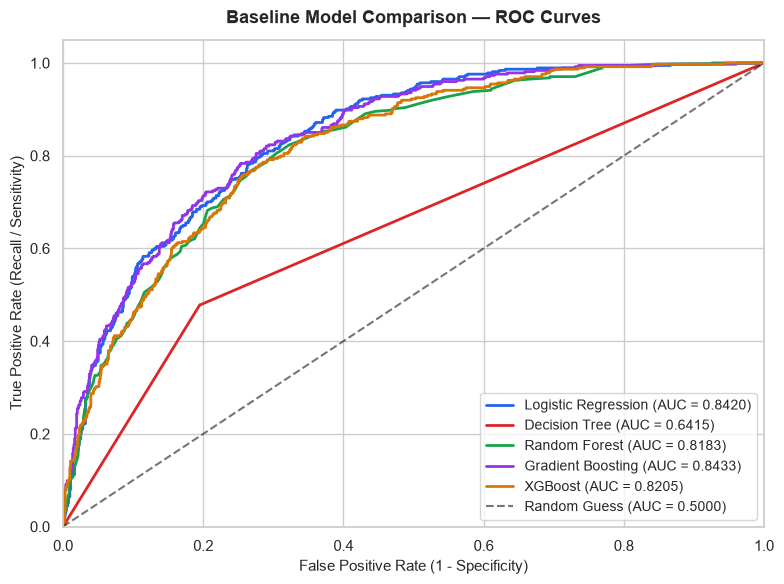

In [8]:
# Generate and display ROC curves
roc_figure_path = os.path.join("..", "reports", "figures", "roc_curves_baseline.png")
if not os.path.exists(os.path.dirname(roc_figure_path)):
    roc_figure_path = os.path.join("reports", "figures", "roc_curves_baseline.png")

fig_roc = plot_roc_curves(evaluations, y_test, save_path=roc_figure_path)
plt.show()


### 7.2 Confusion Matrices
Confusion matrices display exact distributions of True Negatives, False Positives, False Negatives, and True Positives on the 1,409 hold-out test customers.


Confusion matrices saved to: ..\reports\figures\confusion_matrices_baseline.png


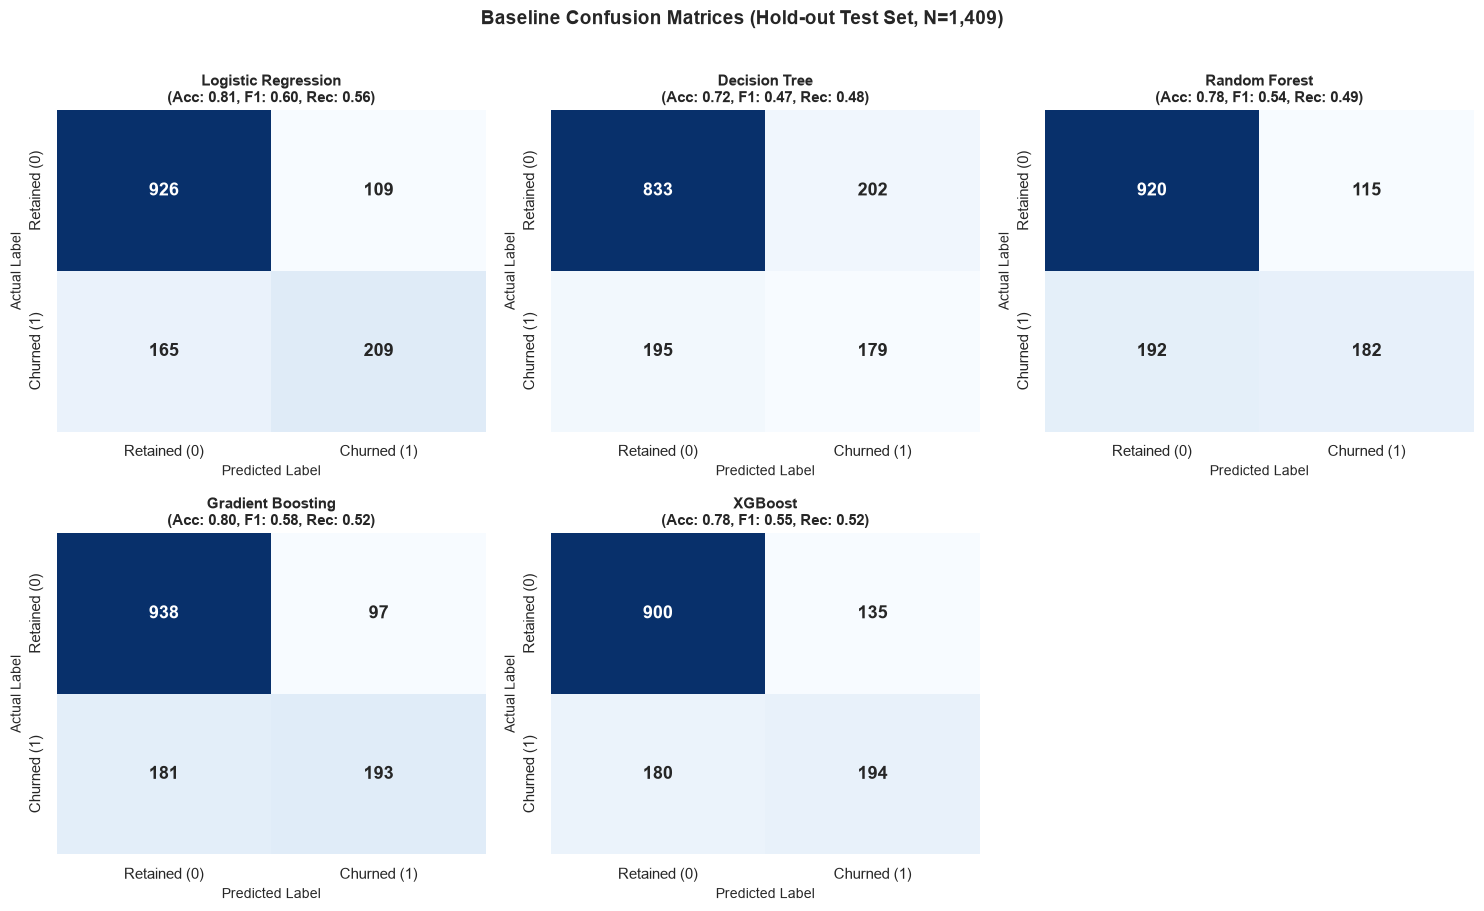

In [9]:
# Generate and display Confusion Matrices grid
cm_figure_path = os.path.join("..", "reports", "figures", "confusion_matrices_baseline.png")
if not os.path.exists(os.path.dirname(cm_figure_path)):
    cm_figure_path = os.path.join("reports", "figures", "confusion_matrices_baseline.png")

fig_cm = plot_confusion_matrices(evaluations, y_test, save_path=cm_figure_path)
plt.show()


## 8. Save Baseline Results

We export the baseline comparison metrics to `reports/model_comparison.csv`.

> **Note:** These models are baseline benchmarks. We do not claim a final production model at this stage. Hyperparameter optimization and threshold selection will be explored in subsequent phases.


In [10]:
# Save baseline metrics table
csv_output_path = os.path.join("..", "reports", "model_comparison.csv")
if not os.path.exists(os.path.dirname(csv_output_path)):
    csv_output_path = os.path.join("reports", "model_comparison.csv")

save_comparison_results(comparison_df, csv_output_path)


Model comparison saved to: ..\reports\model_comparison.csv


## 9. Automated Phase 4 Validation Suite
Programmatic verification confirming that all experimental integrity constraints have been satisfied.


In [11]:
# Run validation checks
checks = {
    "Stratified split size (train=5634, test=1409)": (len(X_train) == 5634 and len(X_test) == 1409),
    "Train and test disjoint (no index overlap)": len(set(X_train.index).intersection(set(X_test.index))) == 0,
    "Train churn proportion matches test within 0.1%": abs(y_train.mean() - y_test.mean()) < 0.001,
    "Preprocessing fitted on train only (features match)": X_train_prep.shape[1] == X_test_prep.shape[1] == 46,
    "All 5 models evaluated": len(comparison_df) == 5,
    "Predictions are valid binary classes {0, 1}": all(set(ev["y_pred"]).issubset({0, 1}) for ev in evaluations.values()),
    "Predicted probabilities bounded in [0, 1]": all(np.all((ev["y_prob"] >= 0.0) & (ev["y_prob"] <= 1.0)) for ev in evaluations.values()),
    "ROC-AUC calculated for all models": all(ev["ROC-AUC"] > 0.5 for ev in evaluations.values()),
}

print("Phase 4 Automated Validation Results:")
print("=" * 60)
for check_name, status in checks.items():
    print(f"• {check_name:<52}: {'PASSED' if status else 'FAILED'}")
print("=" * 60)

assert all(checks.values()), "Phase 4 validation failed!"
print("All Phase 4 validation checks confirmed successfully.")


Phase 4 Automated Validation Results:
• Stratified split size (train=5634, test=1409)       : PASSED
• Train and test disjoint (no index overlap)          : PASSED
• Train churn proportion matches test within 0.1%     : PASSED
• Preprocessing fitted on train only (features match) : PASSED
• All 5 models evaluated                              : PASSED
• Predictions are valid binary classes {0, 1}         : PASSED
• Predicted probabilities bounded in [0, 1]           : PASSED
• ROC-AUC calculated for all models                   : PASSED
All Phase 4 validation checks confirmed successfully.
